# REGRESIÓN POLINÓMICA: PREDICCIÓN DE LA PRIMA DEL SEGURO

# ¿Por qué la *Prima*?

La prima es el precio que el cliente paga a Lagun Aro por el seguro de protección de pagos y, por tanto, la principal fuente de ingresos asociada a cada póliza. Estimarla con precisión es fundamental por tres motivos:

- **Fijación de precios:** permite calcular de forma automática y objetiva el coste del seguro para un nuevo cliente a partir de sus características y de las condiciones del préstamo, sin depender de criterios manuales.
- **Equilibrio entre ingresos y riesgo:** la prima es lo que la aseguradora cobra a cambio de asumir el riesgo de que el cliente deje de pagar. Conocerla permite compararla con la pérdida esperada de cada cliente, calculada a partir de la probabilidad de impago y del valor presente de las cuotas pendientes, y comprobar si el precio cubre el riesgo asumido.
- **Competitividad:** una prima demasiado elevada puede hacer que el cliente opte por otra aseguradora, mientras que una prima demasiado baja no compensa el riesgo. Disponer de una estimación ajustada al perfil de cada cliente ayuda a encontrar el equilibrio.

- Desde el punto de vista técnico, la prima es una variable **continua**, expresada en euros, por lo que su estimación se aborda mediante técnicas de **regresión**. Además, el análisis descriptivo muestra que depende principalmente del importe del préstamo, del endeudamiento del cliente y de la duración, y que esta relación no es lineal, lo que justifica el uso de una regresión polinómica.


## IMPORTAR LIBRERÍAS


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## CARGA DE LOS DATOS

In [ ]:
prestamos=pd.read_excel('datos/datos_limpio_automovil.xlsx')
prestamos.head()

,Unnamed: 0,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,...,Estudios_Escolar,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero
0,0,O77MPJ,26,19153,6973,706,9,1,19.05,36,...,False,True,False,False,False,True,False,False,False,True
1,8,IYOL1S,29,39531,40000,826,0,1,9.74,24,...,False,False,False,False,False,True,False,True,False,False
2,9,FRMZVN,29,40348,16448,740,9,1,14.73,24,...,False,False,True,False,False,True,False,False,False,True
3,26,YKHXVY,38,41732,42040,661,173,2,13.24,48,...,False,True,False,False,False,False,True,True,False,False
4,32,NHDJTK,35,35085,16406,759,181,1,9.74,36,...,True,False,False,False,False,True,False,True,False,False


## ANÁLISIS DESCRIPTIVO

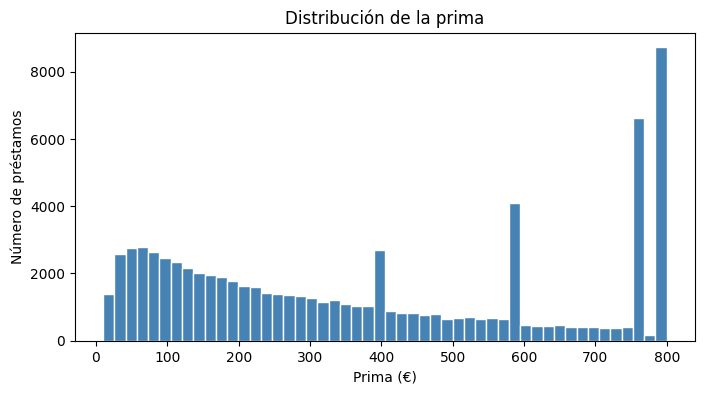

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(prestamos["Prima"], bins=50, color="steelblue", edgecolor="white")
plt.xlabel("Prima (€)")
plt.ylabel("Número de préstamos")
plt.title("Distribución de la prima")
plt.show()

In [ ]:
print(prestamos["Prima"].describe())
primas_max = (prestamos["Prima"] == 800).sum()
print("Préstamos con prima en el tope de 800 €:", primas_max)
print("Porcentaje:", 100 * primas_max / len(prestamos), "%")

count    76924.000000
mean       383.694225
std        267.385642
min         10.000000
25%        137.130000
50%        332.670000
75%        610.615000
max        800.000000
Name: Prima, dtype: float64
Préstamos con prima en el tope de 800 €: 8575
Porcentaje: 11.14736623160522 %


### INTERPRETACIÓN

- La prima media es de 383,69 €, con una desviación típica de 267,39 €, lo que nos dice que hay mucha variabilidad entre clientes.
- Los valores van de 10 € a 800 €. El 11,15 % de los préstamos está exactamente en 800 €, lo que indica que la aseguradora fija un tope máximo de prima. Además, el histograma muestra una acumulación anómala en ese valor.
- Este tope es importante para el modelo: una regresión no sabe que la prima no puede pasar de 800 €, por lo que podría predecir valores por encima.

### MATRIZ DE CORRELACIONES
Mide la relación lineal entre variables (de −1 a 1). Nos interesa sobre todo la correlación de cada variable con Prima, para saber cuáles serán más relevantes en el modelo.

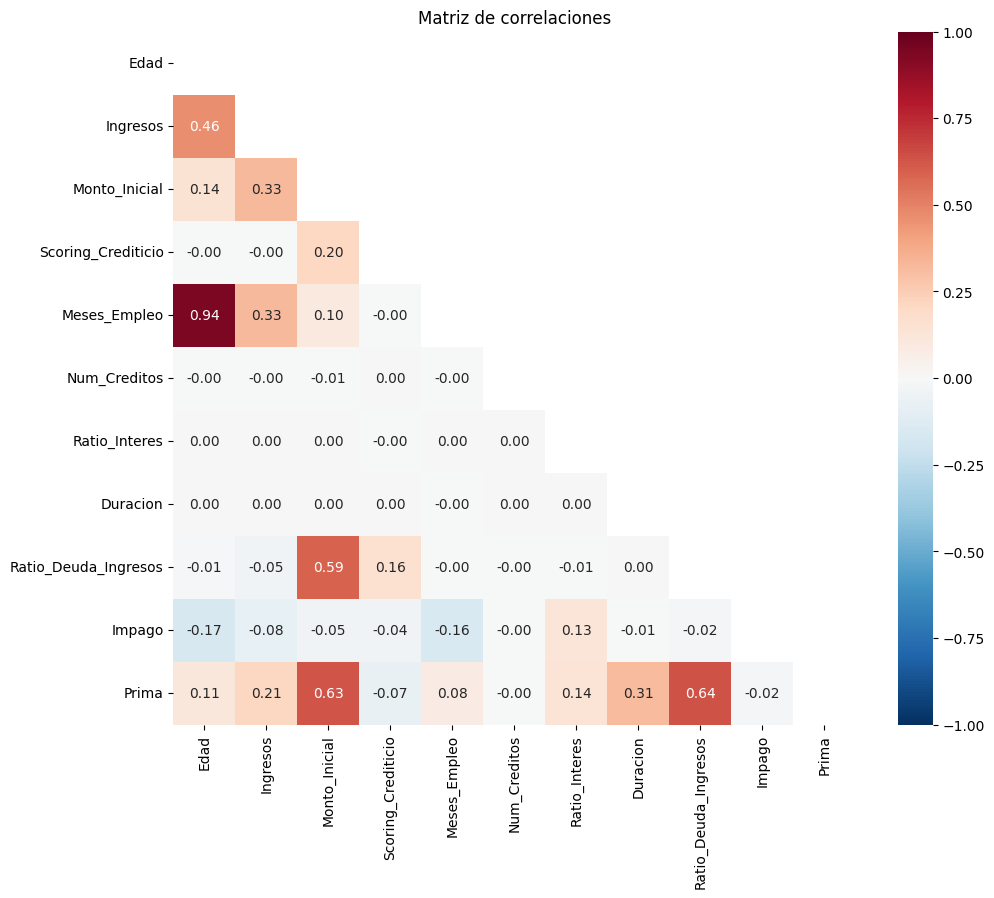

Correlación de cada variable con Prima:
Scoring_Crediticio     -0.073
Impago                 -0.018
Num_Creditos           -0.004
Meses_Empleo            0.084
Edad                    0.113
Ratio_Interes           0.137
Ingresos                0.213
Duracion                0.313
Monto_Inicial           0.627
Ratio_Deuda_Ingresos    0.636
Name: Prima, dtype: float64


In [ ]:
corr = prestamos[["Edad", "Ingresos", "Monto_Inicial", "Scoring_Crediticio", "Meses_Empleo",
                  "Num_Creditos", "Ratio_Interes", "Duracion", "Ratio_Deuda_Ingresos",
                  "Impago", "Prima"]].corr()

plt.figure(figsize=(11, 9))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlaciones")
plt.show()

print("Correlación de cada variable con Prima:")
print(corr["Prima"].drop("Prima").sort_values().round(3))

### INTERPRETACIÓN
Las variables que más se encunetran correlacionadas con la variable objetivo (Prima), son 'Ratio_Deuda_Ingresos' y 'Monto_Inicial', lo que cobra sentido ya que la prima dependerá totalmente de la cantidad de dinero que se preste, durante cuánto dinero se preste y cuanto endeudamiento supondrá al cliente.

In [ ]:
# Prima media por tramos de importe del préstamo
tramos = pd.cut(prestamos["Monto_Inicial"], [0, 5000, 10000, 20000, 40000, 60000, 100000, 400000])
prestamos.groupby(tramos, observed=True)["Prima"].agg(["mean", "count"]).round(1)

,mean,count
Monto_Inicial,,
"(0, 5000]",43.6,4320
"(5000, 10000]",87.0,7739
"(10000, 20000]",157.6,13156
"(20000, 40000]",422.4,29821
"(40000, 60000]",539.7,6783
"(60000, 100000]",664.3,7317
"(100000, 400000]",701.2,7788


# SEPARAR EN X E Y

Variables que eliminamos de X:

- Prima: es la variable que queremos predecir, así que va en y.
- Unnamed: 0 e ID: son identificadores y no aportan información.
- Impago: no se relaciona con la prima y, además, se conoce después de contratar el seguro.
- Estudios_Escolar, Tipo_Jornada_Laboral_Jornada completa y Estado_Civil_Casado: son las categorías de referencia de cada grupo de dummies; se eliminan para evitar multicolinealidad.

Partición: 80 % entrenamiento y 20 % test, con random_state = 42 para que sea reproducible.

In [ ]:
X = prestamos.drop(columns = ['Prima', 'Impago', 'Unnamed: 0', 'ID',
                              'Estudios_Escolar', 'Tipo_Jornada_Laboral_Jornada completa',
                              'Estado_Civil_Casado'])
y = prestamos['Prima']

X_train, X_test, y_train, y_test = train_test_split(
                                        X, y,
                                        train_size   = 0.8,
                                        random_state = 42,
                                        shuffle      = True)

print("Variables explicativas:", X.shape[1])
print("Observaciones train:", X_train.shape[0], "| test:", X_test.shape[0])

Variables explicativas: 20
Observaciones train: 61539 | test: 15385


### ESCALAR

Utilizamos `StandardScaler` para que todas las variables tengan una media 0 y desviación típica 1.

En la regresión polinómica es especialmente importante, porque al elevar al cuadrado o al cubo variables grandes, como el importe del préstamo, se obtienen valores enormes que dan problemas en los cálculos.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# MODELO DE REFERENCIA: REGRESIÓN LINEAL MÚLTIPLE

In [ ]:
modelo_lineal = LinearRegression().fit(X_train_scaled, y_train)

pred_train_lineal = modelo_lineal.predict(X_train_scaled)
pred_test_lineal = modelo_lineal.predict(X_test_scaled)

print("R² train:", round(r2_score(y_train, pred_train_lineal), 3))
print("R² test: ", round(r2_score(y_test, pred_test_lineal), 3))
print("RMSE test:", round(mean_squared_error(y_test, pred_test_lineal) ** 0.5, 2), "€")
print("MAE test: ", round(mean_absolute_error(y_test, pred_test_lineal), 2), "€")

R² train: 0.679
R² test:  0.677
RMSE test: 152.16 €
MAE test:  119.96 €


### INTERPRETACIÓN:

- MAE = 120 €: de media se equivoca en unos 120 €, un error elevado teniendo en cuenta que la prima media es de 384 €.
- El R² es prácticamente igual en entrenamiento (0,679) y en test (0,677), por lo que el modelo no se ajusta en exceso a los datos: el problema es que resulta demasiado simple para la forma curva de los datos.

# VALIDACIÓN CRUZADA
Un modelo con buenos resultados en los datos de entrenamiento pero peores en datos nuevos se está ajustando en exceso a los datos históricos (sobreajuste). Un modelo con malos resultados en ambos casos es demasiado simple (subajuste).

Para evaluar la capacidad de cada modelo de predecir correctamente la prima de nuevos clientes, se utiliza la **validación cruzada**. El conjunto de entrenamiento se divide en 5 partes y el modelo se entrena 5 veces, utilizando en cada ocasión una parte distinta para validar. El resultado final es la media de las 5 evaluaciones, lo que evita que la conclusión dependa de una única división de los datos. Se compara el error (RMSE) de los modelos de grado 1, 2 y 3. No se evalúan grados superiores, ya que el grado 4 generaría más de 10.000 variables, lo que resulta inviable con este volumen de datos.


In [ ]:
for grado in [1, 2, 3]:
    clase_poly = PolynomialFeatures(degree=grado, include_bias=False)
    X_train_grado = clase_poly.fit_transform(X_train_scaled)

    scores = cross_val_score(LinearRegression(), X_train_grado, y_train, cv=5,
                             scoring="neg_root_mean_squared_error")

    # Scikit-learn devuelve el error en negativo ("mayor = mejor"), le cambiamos el signo
    print(f"Grado {grado}: RMSE medio = {-scores.mean():.2f} €  (desviación = {scores.std():.2f})")

Grado 1: RMSE medio = 151.41 €  (desviación = 0.49)
Grado 2: RMSE medio = 97.60 €  (desviación = 0.32)
Grado 3: RMSE medio = 76.08 €  (desviación = 0.28)


**Interpretación.**
- El error de validación disminuye de forma clara al aumentar el grado: 151 € con el modelo lineal, 98 € con grado 2 y 76 € con grado 3.
- La desviación entre las 5 evaluaciones es muy reducida, por lo que los resultados son estables y no dependen de la división de los datos.
- El modelo de grado 3 es el que ofrece mejores estimaciones sobre clientes no utilizados en el entrenamiento.

# CURVAS DE APRENDIZAJE

Las curvas de aprendizaje representan el error del modelo en entrenamiento y en validación a medida que se incrementa el número de préstamos utilizados para entrenarlo. Permiten diagnosticar si el modelo es demasiado simple, si se ajusta en exceso a los datos o si ha alcanzado un equilibrio adecuado.

En primer lugar, se analiza el modelo lineal.

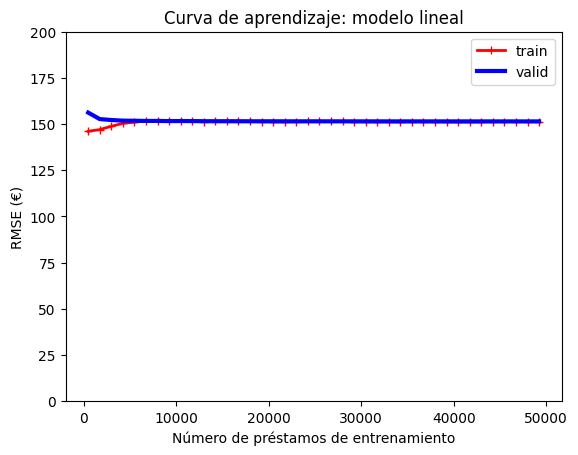

In [ ]:
train_sizes, train_scores, valid_scores = learning_curve(LinearRegression(), X_train_scaled, y_train,
                                                         train_sizes=np.linspace(0.01, 1.0, 40),
                                                         cv=5, scoring="neg_root_mean_squared_error")

# Promediamos los 5 folds y cambiamos el signo para volver al RMSE real
train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
plt.ylim(0, 200)
plt.legend()
plt.xlabel("Número de préstamos de entrenamiento")
plt.ylabel("RMSE (€)")
plt.title("Curva de aprendizaje: modelo lineal")
plt.show()

**Interpretación.** El modelo lineal es demasiado simple para los datos. Las curvas de entrenamiento y validación se aproximan rápidamente y se estabilizan en un error elevado, en torno a 151 €. Una relación lineal no puede representar adecuadamente unos datos con forma curva, por lo que el error no disminuye aunque se incremente el número de préstamos. En esta situación, disponer de más datos no mejora los resultados: es necesario un modelo más flexible.


A continuación, se analiza el modelo de grado 3.


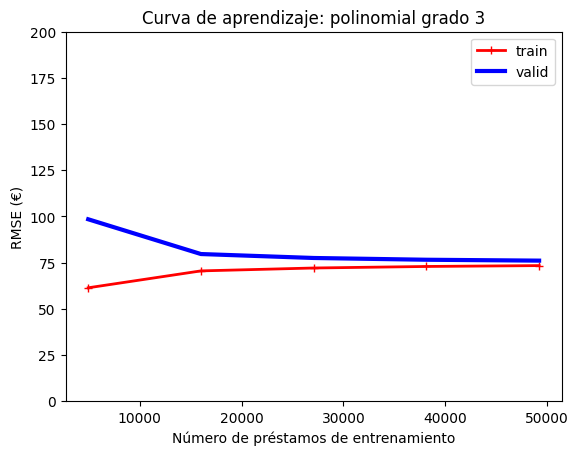

In [ ]:
train_sizes, train_scores, valid_scores = learning_curve(LinearRegression(), X_train_grado_3, y_train,
                                                         train_sizes=np.linspace(0.1, 1.0, 5),
                                                         cv=5, scoring="neg_root_mean_squared_error")

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
plt.ylim(0, 200)
plt.legend()
plt.xlabel("Número de préstamos de entrenamiento")
plt.ylabel("RMSE (€)")
plt.title("Curva de aprendizaje: polinomial grado 3")
plt.show()

**Interpretación.**
- El error es notablemente inferior al del modelo lineal.
- Con un número reducido de préstamos se observa una separación entre ambas curvas: el modelo obtiene mejores resultados en entrenamiento que en validación, ya que dispone de 1.770 variables para un número limitado de observaciones. A medida que aumenta el número de préstamos, el error de validación disminuye y ambas curvas convergen en torno a 74–76 €.
- Con el volumen de datos disponible, el modelo de grado 3 no se ajusta en exceso a los datos históricos y alcanza un equilibrio adecuado entre precisión y capacidad de generalización.

# EQUILIBRIO ENTRE SESGO Y VARIANZA

El error de un modelo depende de dos factores. El sesgo aparece cuando el modelo parte de una suposición equivocada sobre los datos, como ocurre con el modelo lineal, que asume una relación recta entre las variables y la prima cuando en realidad es curva. La varianza aparece cuando el modelo es tan flexible que se vuelve demasiado sensible a los datos con los que se entrena, lo que reduce su capacidad de predicción sobre nuevos clientes.

Al aumentar el grado del polinomio, el sesgo disminuye pero la varianza aumenta. Las curvas de aprendizaje reflejan este equilibrio: el modelo lineal presenta un sesgo elevado, con un error alto tanto en entrenamiento como en validación, mientras que el modelo de grado 3 muestra signos de varianza cuando se entrena con pocos préstamos, con una clara separación entre ambas curvas. En este caso, el elevado número de préstamos disponibles permite que el modelo de grado 3 reduzca el sesgo sin que la varianza se incremente de forma significativa, por lo que constituye el mejor equilibrio entre ambos factores.

# MODELO FINAL: REGRESIÓN POLINÓMICA DE GRADO 3

La elección del modelo de grado 3 se basa en los resultados obtenidos en las fases anteriores:

- Validación cruzada: es el modelo con menor error sobre préstamos no utilizados en el entrenamiento, con un RMSE de 76 €, frente a 98 € del grado 2 y 151 € del modelo lineal. Además, la desviación entre las 5 particiones es muy reducida, por lo que su ventaja es estable y no depende de la división de los datos.
- Curvas de aprendizaje: con el volumen total de datos disponible, el error de entrenamiento (73 €) y el de validación (76 €) son prácticamente iguales, lo que indica que el modelo no se ajusta en exceso a los datos históricos.
- Equilibrio entre sesgo y varianza: el modelo de grado 3 reduce el sesgo del modelo lineal sin que la varianza aumente de forma significativa, gracias al elevado número de préstamos disponibles.
- Viabilidad computacional: no se evalúan grados superiores, ya que el grado 4 generaría más de 10.000 variables, lo que resulta inviable con este volumen de datos.
- Una vez seleccionado el modelo, se evalúa sobre el conjunto de test, formado por préstamos que se apartaron al inicio del análisis en el tran/test y que no se han utilizado en ninguna fase del entrenamiento ni de la selección del modelo. De este modo se obtiene una estimación realista de su precisión sobre nuevos clientes.


In [ ]:
pred_test_grado_3 = modelo_polinomico_grado_3.predict(X_test_grado_3)

print("R² train:", round(modelo_polinomico_grado_3.score(X_train_grado_3, y_train), 3))
print("R² test: ", round(modelo_polinomico_grado_3.score(X_test_grado_3, y_test), 3))
print("RMSE test:", round(mean_squared_error(y_test, pred_test_grado_3) ** 0.5, 2), "€")
print("MAE test: ", round(mean_absolute_error(y_test, pred_test_grado_3), 2), "€")

R² train: 0.924
R² test:  0.921
RMSE test: 75.44 €
MAE test:  56.31 €


**Interpretación.**
- El modelo de grado 3 explica el 92,1 % de la variabilidad de la prima en test, frente al 67,7 % del modelo lineal.
- El error medio es de 56 €, frente a los 120 € del modelo lineal, lo que supone reducir el error a menos de la mitad.
- El R² es prácticamente igual en entrenamiento (0,924) y en test (0,921), lo que confirma que el modelo mantiene su precisión sobre nuevos clientes y no se ajusta en exceso a los datos históricos.

# RESUMEN DE RESULTADOS

- **Lineal (grado 1):** R² de 0,677, error medio de 120 € y error en validación cruzada (RMSE) de 151 €.
- **Polinómico de grado 2:** R² de 0,868, error medio de 74 € y error en validación cruzada (RMSE) de 98 €.
- **Polinómico de grado 3:** R² de 0,921, error medio de 56 € y error en validación cruzada (RMSE) de 76 €.

El modelo de grado 3 es el que mejores resultados obtiene en todas las métricas: explica el 92,1 % de la variabilidad de la prima, se equivoca de media en 56 € (menos de la mitad que el modelo lineal) y presenta el menor error en validación cruzada. Por ello, es el modelo seleccionado.